# Lab 2 : Classification

## G3 SDI - Machine Learning

In this lab, we will tackle a binary classification problem. We are going to use the MNIST dataset, which contains 28x28 images of handwritten digits. More precisely, our goal will be to distinguish between 3s and 5s using logistic regression and K-nearest neighbors.

### Instructions
* Rename your notebook with your surnames as `lab2_Name1_Name2.ipynb`, and include your names in the notebook.
* Your code, and its output, must be commented !
* Please upload your notebook on Moodle in the dedicated section before the deadline.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Report written by [name1], [name2], date.
</div>

In [1]:
# Import usual libraries
import numpy as np
from matplotlib import pyplot as plt
seed = np.random.seed(42)

**Q1.** Load the data from the `.npy` files included in the archive (use `np.load`). How many examples are there ? How many features ? What do the values of the features represent ?

In [2]:
data3 = np.load("data3.npy")
print(data3.shape[0], data3.shape[1])
#print(np.sum(np.isnan(data3)))
#print(data3[(data3.shape[0]+1)//2, (data3.shape[1])//2])


data5 = np.load("data5.npy")
print(data5.shape[0], data5.shape[1])

1037 784
963 784


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Il y a 2000 exemples (1037 images de 3 et 963 images de 5) et 784 features par exemple. Il n’y a pas de valeurs manquantes (0 NaN). Chaque feature est l’intensité d’un pixel de l’image en niveaux de gris.
</div>

**Q2.** Display a few examples of 3, and a few examples of 5 (use `plt.imshow`). Comment.

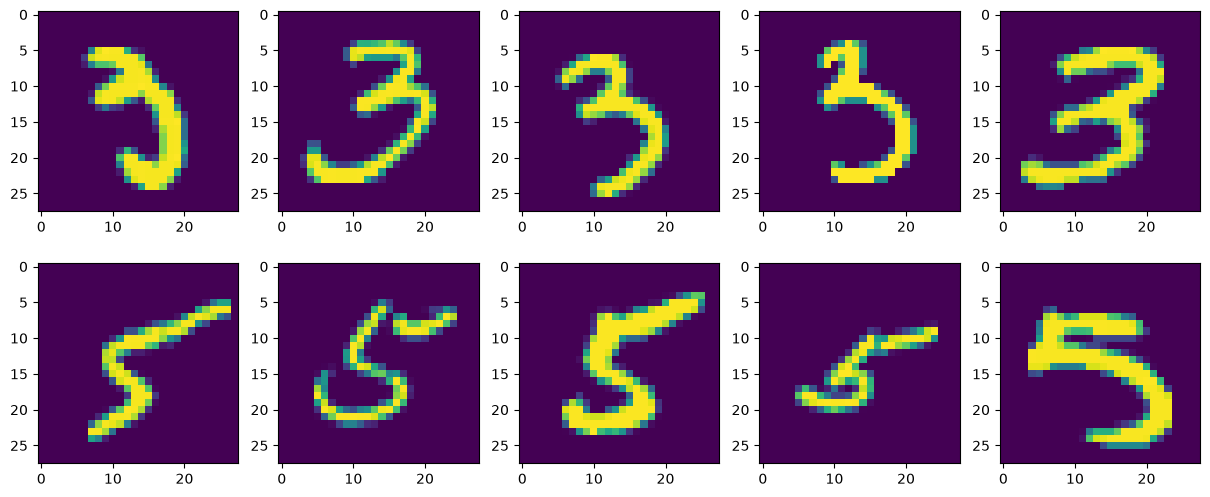

In [3]:
fig, ax = plt.subplots(2, 5, figsize= (15, 6))
for i in range(5):
    ax[0,i].imshow(data3[np.random.randint(0, data3.shape[0]), :].reshape(28,28))
    ax[1,i].imshow(data5[np.random.randint(0, data5.shape[0]), :].reshape(28,28))

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Certains exemples mal écrits sont ambigus, même pour un humain, ce qui annonce des erreurs de classification.
</div>

**Q3.** Create a variable X which contains all the images (use `np.vstack`), and a variable y which encodes the class.

Normalize the features between 0 and 1.

In [4]:
import numpy as np

data_t = data3.copy()
data_f = data5.copy()

data_t = np.hstack((data_t, np.zeros((data_t.shape[0], 1))))
data_f = np.hstack((data_f, np.ones((data_f.shape[0], 1))))

data = np.vstack((data_t, data_f))

X = data[:, :-1]
y = data[:, -1]

X = X/255

**Q4.** Split the dataset into a training set and a test set, using 20% of the original dataset for the test set. Do not forget to set the random state.

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state= 42)

**Q5.** Train a logistic regression model on the training set (see documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)). Recall how the coefficients are obtained.

What does scikit-learn do by default that does not match what we studied during the lecture ?

In [6]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression().fit(X_train, y_train)
coefs = model.coef_
intercept = model.intercept_
print(intercept)

[3.14088116]


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Les coefficients $(w, b)$ sont obtenus par maximum de vraisemblance. On modélise $P(y=1\mid x)=\sigma(w^\top x+b)$ et on minimise l’opposé de la log-vraisemblance (l’entropie croisée) $-\sum_i [y_i\log p_i+(1-y_i)\log(1-p_i)]$. Il n’y a pas de solution analytique, donc on utilise une méthode itérative (descente de gradient en cours, lbfgs dans scikit-learn). Le problème est convexe, donc on converge vers l’optimum global.

Scikit-learn  ajoute une pénalité de régularisation L2 sur les poids (penalty='l2', C=1.0). Il minimise donc l’entropie croisée plus $\frac{1}{2C}\|w\|^2$, alors que le cours présente la régression logistique sans régularisation.

</div>

**Q6.** Compute the accuracy on the test set.

In [7]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_pred, y_test)
print("Accuracy on the test test : ",  accuracy)

Accuracy on the test test :  0.955


**Q7.** Display the confusion matrix from the test set (add label names), and interpret it.

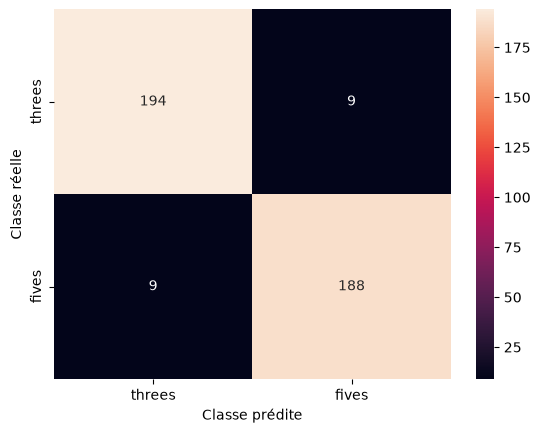

recall = 0.9543147208121827
precision = 0.9543147208121827
f1 =  0.9543147208121827


In [8]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score
import seaborn as sns

m = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    m,
    annot=True,
    fmt=".0f",
    xticklabels=["threes", "fives"],
    yticklabels=["threes", "fives"]
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()

print("recall =", recall_score(y_test, y_pred))
print("precision =", precision_score(y_test, y_pred))
print("f1 = ", f1_score(y_test, y_pred))

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Le modèle se trompe 18 fois sur 400 (4,5 %), avec autant de 3 pris pour des 5 que de 5 pris pour des 3. Il n’est donc pas biaisé vers une classe, ce qui explique que précision, rappel et F1 soient égaux (≈ 0,954).
</div>

**Q8.** Display an example where a 3 was mistaken for 5, and vice versa. Comment.

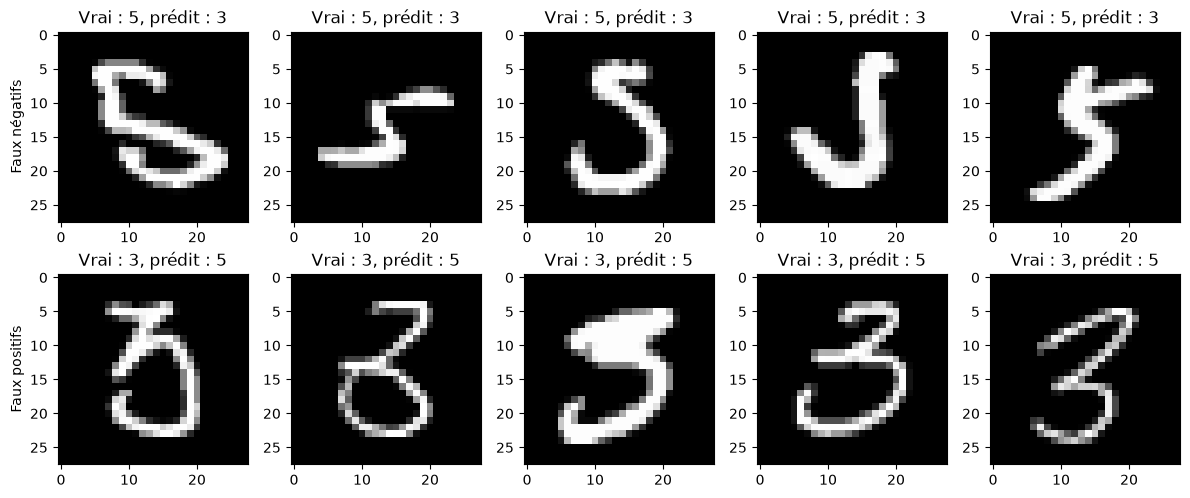

In [9]:
false_negatives_indices = np.where((y_test == 1) & (y_pred == 0))[0]
false_positives_indices = np.where((y_test == 0) & (y_pred == 1))[0]

n =5

fig, axes = plt.subplots(2, n, figsize=(12, 5))

# Faux négatifs
for j, i in enumerate(np.random.choice(
    false_negatives_indices,
    size=min(n, len(false_negatives_indices)),
    replace=False
)):
    axes[0, j].imshow(X_test[i].reshape(28, 28), cmap="gray")
    axes[0, j].set_title(f"Vrai : 5, prédit : 3")

# Faux positifs
for j, i in enumerate(np.random.choice(
    false_positives_indices,
    size=min(n, len(false_positives_indices)),
    replace=False
)):
    axes[1, j].imshow(X_test[i].reshape(28, 28), cmap="gray")
    axes[1, j].set_title("Vrai : 3, prédit : 5")

axes[0, 0].set_ylabel("Faux négatifs")
axes[1, 0].set_ylabel("Faux positifs")

plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Les erreurs concernent des chiffres ambigus : des 3 dont le haut est aplati ou ouvert, qui ressemblent à des 5, et des 5 dont la barre du haut est peu marquée ou dont le bas est très arrondi, qui ressemblent à des 3. Le modèle linéaire raisonne pixel par pixel, sans notion de forme globale, donc il est sensible aux variations d’écriture et se trompe sur ces cas limites.
</div>

**Q9.** As we have seen during the lecture, the logistic regression model does not directly output a 0 or a 1, but rather the probability of being 0 or 1 (given x), which can be accessed with the `.predict_proba` attribute. This probability is then compared to a threshold to output the prediction, the default threshold being 0.5.

Recall what is the underlying assumption of using a threshold of 0.5.

Display the evolution of the precision and recall (using the 5s as the reference class), as well as the F1-score, when the threshold varies between 0 and 1. Comment.

Text(0.5, 1.0, 'evolution of metrics along treshold value')

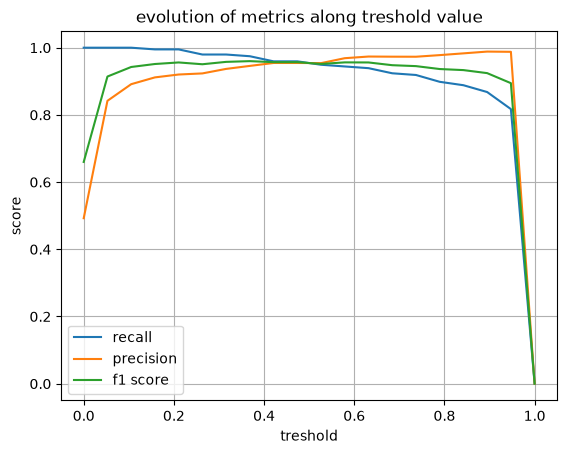

In [13]:
tresholds = np.linspace(0,1, 20)
y_proba = model.predict_proba(X_test)
recalls = []
precisions = []
f1_scores = []
for tr in tresholds :
    y_res = (y_proba[:,1] > tr).astype(int)
    recalls.append(recall_score(y_test, y_res))
    precisions.append(precision_score(y_test, y_res, zero_division=0))
    f1_scores.append(f1_score(y_test, y_res))
plt.plot(tresholds, recalls, label = "recall")
plt.plot(tresholds, precisions, label = "precision")
plt.plot(tresholds, f1_scores, label = "f1 score")
plt.legend()
plt.xlabel("treshold")
plt.ylabel("score")
plt.grid()
plt.title("evolution of metrics along treshold value")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Le seuil de 0,5 revient à prédire la classe la plus probable. Il suppose que les deux types d’erreur ont le même coût (une erreur sur un 3 est aussi grave qu’une erreur sur un 5) et que les probabilités sont bien estimées.

Le F1 est maximal sur un plateau autour de 0,5, ce qui confirme que ce seuil est un bon choix ici.

Si on voulait ne manquer aucun 5, on baisserait le seuil, au prix de plus de fausses alertes.
</div>

**Q10.** Lastly, we would like to check the performance of KNN on this dataset. To do so, select the optimal value of $K$ by cross-validation on the training set, and then compute the accuracy score of the optimal KNN on the test set. Comment.

In [11]:
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

K_values = range(1, 21)
scores = []

for k in K_values:
    model_k = KNeighborsClassifier(n_neighbors=k)

    cv_scores = cross_val_score(model_k, X_train, y_train, cv=5, scoring="accuracy")

    scores.append(cv_scores.mean())

best_k = list(K_values)[np.argmax(scores)]

print("Meilleur K :", best_k)
print("Accuracy :" ,max(scores))

model_k = KNeighborsClassifier(n_neighbors = best_k).fit(X_train, y_train)

y_predk = model_k.predict(X_test)
print("Accuracy on the test set:", accuracy_score(y_test, y_predk))


Meilleur K : 5
Accuracy : 0.9775
Accuracy on the test set: 0.985


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Le KNN est meilleur ici car il a une frontière de décision non linéaire : les images d’une même classe forment des groupes proches dans l’espace des pixels. La régression logistique est limitée à une frontière linéaire. Le prix à payer pour le KNN est un coût de prédiction élevé (calcul de distances en dimension 784 avec tout le jeu d’entraînement).
</div>